# Regresión Lineal con Varias Variables

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Ahora el precio de la casa depende de **tres** factores (features): área, número de habitaciones y antigüedad. El modelo aprende un coeficiente para cada uno.

## 1. El problema

Queremos predecir el precio de una casa usando varias variables a la vez:

$$\text{precio} = m_1\cdot\text{área} + m_2\cdot\text{habitaciones} + m_3\cdot\text{antigüedad} + b$$

Aquí **área, habitaciones y antigüedad** son las variables independientes (features) y **precio** es la variable dependiente.

In [1]:
import pandas as pd
import numpy as np
from sklearn import linear_model

Cargamos los datos. Fíjate que a una fila le falta el número de habitaciones (valor vacío / NaN).

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/homeprices_multi.csv')
df

,area,bedrooms,age,price
0,2600,3.0,20,550000
1,3000,4.0,15,565000
2,3200,NaN,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000
5,4100,6.0,8,810000


## 2. Limpieza de datos

Hay un dato faltante en `bedrooms`. Lo rellenamos con la **mediana** de la columna (una práctica común para no perder la fila).

In [3]:
df.bedrooms.median()

np.float64(4.0)

In [4]:
df.bedrooms = df.bedrooms.fillna(df.bedrooms.median())
df

,area,bedrooms,age,price
0,2600,3.0,20,550000
1,3000,4.0,15,565000
2,3200,4.0,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000
5,4100,6.0,8,810000


Entrenamos la regresión con las tres variables de entrada (todo menos el precio).

In [5]:
reg = linear_model.LinearRegression()
reg.fit(df.drop('price', axis='columns'), df.price)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 112.06,23388.88,-3231.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['area','bedrooms','age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.213e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


Vemos los coeficientes (uno por variable) y el intercepto.

In [6]:
reg.coef_

array([  112.06244194, 23388.88007794, -3231.71790863])

In [7]:
reg.intercept_

np.float64(221323.00186540402)

**Predecir:** casa de 3000 pies², 3 habitaciones, 40 años de antigüedad.

In [8]:
reg.predict([[3000, 3, 40]])

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([498408.25158031])

**Predecir:** casa de 2500 pies², 4 habitaciones, 5 años de antigüedad.

In [9]:
reg.predict([[2500, 4, 5]])

/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([578876.03748933])

Una gráfica útil: comparamos el **precio real** con el **precio predicho** por el modelo para las casas de entrenamiento. Mientras más cerca de la línea diagonal, mejor el ajuste.

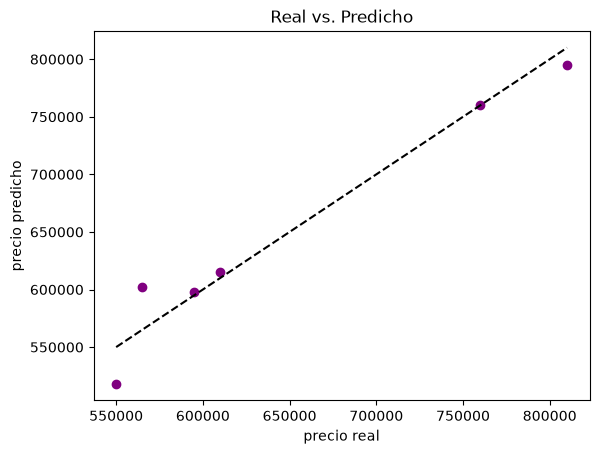

In [10]:
import matplotlib.pyplot as plt
pred = reg.predict(df.drop('price', axis='columns'))
plt.scatter(df.price, pred, color='purple')
plt.plot([df.price.min(), df.price.max()], [df.price.min(), df.price.max()], 'k--')
plt.xlabel('precio real')
plt.ylabel('precio predicho')
plt.title('Real vs. Predicho')
plt.show()

## Ejercicio práctico

**Enunciado (del curso):** Con el archivo `hiring.csv`, predecir el **salario** de un candidato a partir de tres variables: años de **experiencia**, puntaje en la **prueba escrita** (sobre 10) y puntaje en la **entrevista** (sobre 10).

Preguntas:
1. Salario de un candidato con **2 años de experiencia, 9 en la prueba y 6 en la entrevista**.
2. Salario de un candidato con **12 años de experiencia, 10 en la prueba y 10 en la entrevista**.

**Paso 1.** Cargamos los datos. La experiencia viene escrita en **palabras** (two, three, ...) y hay valores faltantes.

In [11]:
df_h = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/hiring.csv')
df_h

,experience,test_score(out of 10),interview_score(out of 10),salary($)
0,NaN,8.0,9,50000
1,NaN,8.0,6,45000
2,five,6.0,7,60000
3,two,10.0,10,65000
4,seven,9.0,6,70000
5,three,7.0,10,62000
6,ten,NaN,7,72000
7,eleven,7.0,8,80000


**Paso 2.** Limpiamos:
- La **experiencia** en palabras la convertimos a número (sin experiencia = 0).
- El puntaje de prueba faltante lo rellenamos con la mediana.

In [12]:
df_h.columns = ['experience', 'test_score', 'interview_score', 'salary']

palabras = {'one':1,'two':2,'three':3,'four':4,'five':5,'six':6,
            'seven':7,'eight':8,'nine':9,'ten':10,'eleven':11,'twelve':12}

df_h.experience = df_h.experience.fillna('zero')
df_h.experience = df_h.experience.apply(lambda x: palabras.get(str(x).strip().lower(), 0))

df_h.test_score = df_h.test_score.fillna(df_h.test_score.median())
df_h

,experience,test_score,interview_score,salary
0,0,8.0,9,50000
1,0,8.0,6,45000
2,5,6.0,7,60000
3,2,10.0,10,65000
4,7,9.0,6,70000
5,3,7.0,10,62000
6,10,8.0,7,72000
7,11,7.0,8,80000


**Paso 3.** Entrenamos la regresión múltiple: experiencia + prueba + entrevista → salario.

In [13]:
reg_h = linear_model.LinearRegression()
reg_h.fit(df_h[['experience','test_score','interview_score']], df_h.salary)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[2812.95,1845.71,2205.24]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['experience','test_score','interview_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.774e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


**Paso 4.** Respondemos las dos preguntas del ejercicio.

In [14]:
p1 = reg_h.predict([[2, 9, 6]])
p2 = reg_h.predict([[12, 10, 10]])
print(f"(1) 2 años exp, 9 prueba, 6 entrevista -> US$ {p1[0]:,.2f}")
print(f"(2) 12 años exp, 10 prueba, 10 entrevista -> US$ {p2[0]:,.2f}")

(1) 2 años exp, 9 prueba, 6 entrevista -> US$ 53,205.97
(2) 12 años exp, 10 prueba, 10 entrevista -> US$ 92,002.18


/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/luiscorreamatos/curso_ia_india/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


**Paso 5.** Gráfica: salario real vs. salario predicho por el modelo.

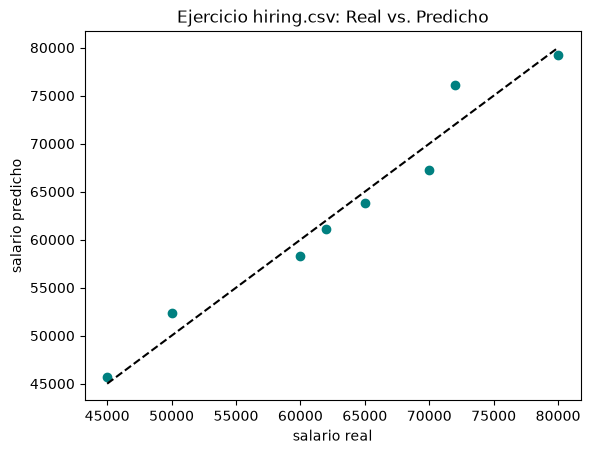

In [15]:
pred_h = reg_h.predict(df_h[['experience','test_score','interview_score']])
plt.scatter(df_h.salary, pred_h, color='teal')
plt.plot([df_h.salary.min(), df_h.salary.max()], [df_h.salary.min(), df_h.salary.max()], 'k--')
plt.xlabel('salario real')
plt.ylabel('salario predicho')
plt.title('Ejercicio hiring.csv: Real vs. Predicho')
plt.show()

**Conclusión:** el candidato con más experiencia y mejores puntajes recibe un salario estimado mayor, como era de esperar. El modelo capturó la relación entre las tres variables y el salario.